<a href="https://colab.research.google.com/github/Varnika1024/DLAC/blob/main/SKILL/Skill6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!pip install -q ultralytics

import os
import glob
import shutil
import xml.etree.ElementTree as ET
import cv2
import yaml
import torch
from ultralytics import YOLO

# 1. Inspect the downloaded Kaggle dataset structure
image_exts = {".jpg", ".jpeg", ".png"}
all_imgs, xmls, txts = [], [], []
for root, dirs, files in os.walk(dataset_path):
  for f in files:
    fp = os.path.join(root, f)
    ext = os.path.splitext(f)[1].lower()
    if ext in image_exts:
      all_imgs.append(fp)
    elif ext == ".xml":
      xmls.append(fp)
    elif ext == ".txt" and f.lower() != "classes.txt":
      txts.append(fp)

print(f"Found {len(all_imgs)} images | {len(xmls)} XML files | {len(txts)} TXT files")

# 2. Build a clean YOLO-formatted dataset folder for training
yolo_ds = "/content/indian_vehicle_yolo"
if os.path.exists(yolo_ds):
  shutil.rmtree(yolo_ds)
for sub in ["images/train", "images/val", "labels/train", "labels/val"]:
  os.makedirs(os.path.join(yolo_ds, sub), exist_ok=True)

img_map = {os.path.splitext(os.path.basename(p))[0]: p for p in all_imgs}
class_list = []

if xmls:
  print("Converting XML bounding-box annotations to YOLO format...")
  valid_pairs = []
  for xp in xmls:
    tree = ET.parse(xp)
    root = tree.getroot()
    stem = os.path.splitext(os.path.basename(xp))[0]
    if stem not in img_map:
      fname_node = root.find("filename")
      if fname_node is not None:
        stem = os.path.splitext(fname_node.text)[0]
    if stem not in img_map:
      continue

    img = cv2.imread(img_map[stem])
    if img is None:
      continue
    ih, iw, _ = img.shape

    yolo_lines = []
    for obj in root.findall("object"):
      cname = obj.find("name").text.strip()
      if cname not in class_list:
        class_list.append(cname)
      cid = class_list.index(cname)
      bnd = obj.find("bndbox")
      xmin, ymin = float(bnd.find("xmin").text), float(bnd.find("ymin").text)
      xmax, ymax = float(bnd.find("xmax").text), float(bnd.find("ymax").text)
      xc = ((xmin + xmax) / 2.0) / iw
      yc = ((ymin + ymax) / 2.0) / ih
      bw = (xmax - xmin) / iw
      bh = (ymax - ymin) / ih
      if 0 < bw <= 1 and 0 < bh <= 1:
        yolo_lines.append(f"{cid} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

    if yolo_lines:
      valid_pairs.append((img_map[stem], stem, yolo_lines))

  valid_pairs = valid_pairs[:400]
  split_idx = max(1, int(0.8 * len(valid_pairs)))

  for i, (ipath, stem, lines) in enumerate(valid_pairs):
    split = "train" if i < split_idx else "val"
    shutil.copy(ipath, f"{yolo_ds}/images/{split}/{stem}.jpg")
    with open(f"{yolo_ds}/labels/{split}/{stem}.txt", "w") as lf:
      lf.write("\n".join(lines))

elif txts:
  print("Using existing YOLO TXT annotations...")
  valid_pairs = []
  for tp in txts:
    stem = os.path.splitext(os.path.basename(tp))[0]
    if stem in img_map:
      valid_pairs.append((img_map[stem], tp, stem))
  valid_pairs = valid_pairs[:400]
  split_idx = max(1, int(0.8 * len(valid_pairs)))
  max_cid = 0
  for i, (ipath, tpath, stem) in enumerate(valid_pairs):
    split = "train" if i < split_idx else "val"
    shutil.copy(ipath, f"{yolo_ds}/images/{split}/{stem}.jpg")
    shutil.copy(tpath, f"{yolo_ds}/labels/{split}/{stem}.txt")
    with open(tpath) as f:
      for line in f:
        if line.strip():
          max_cid = max(max_cid, int(line.split()[0]))
  class_list = [f"vehicle_{c}" for c in range(max_cid + 1)]
else:
  raise ValueError("No XML or TXT bounding-box labels found in this Kaggle dataset!")

# 3. Write data.yaml and Train YOLOv8n on the Indian Vehicle Dataset
data_yaml_path = f"{yolo_ds}/data.yaml"
with open(data_yaml_path, "w") as yf:
  yaml.dump(
      {
          "path": yolo_ds,
          "train": "images/train",
          "val": "images/val",
          "nc": len(class_list),
          "names": class_list,
      },
      yf,
  )

print(f"Prepared {len(valid_pairs)} labeled Indian traffic images across classes: {class_list}")
print("Training YOLOv8n model on T4 GPU...")

device_id = 0 if torch.cuda.is_available() else "cpu"
train_model = YOLO("yolov8n.pt")
train_model.train(
    data=data_yaml_path,
    epochs=10,
    imgsz=640,
    batch=16,
    device=device_id,
    project="/content/runs",
    name="indian_vehicle_detector",
    exist_ok=True,
)
print("\nTraining complete! Custom weights saved at: /content/runs/indian_vehicle_detector/weights/best.pt")

Found 100 images | 100 XML files | 0 TXT files
Converting XML bounding-box annotations to YOLO format...
Prepared 100 labeled Indian traffic images across classes: ['two_wheelers', 'auto', 'vehicle_truck', 'bicycle', 'tractor', 'bus', 'car', 'concrete_mixer', 'tempo', 'truck_tanker']
Training YOLOv8n model on T4 GPU...
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/indian_vehicle_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.

Saving images (1).jpeg to images (1).jpeg


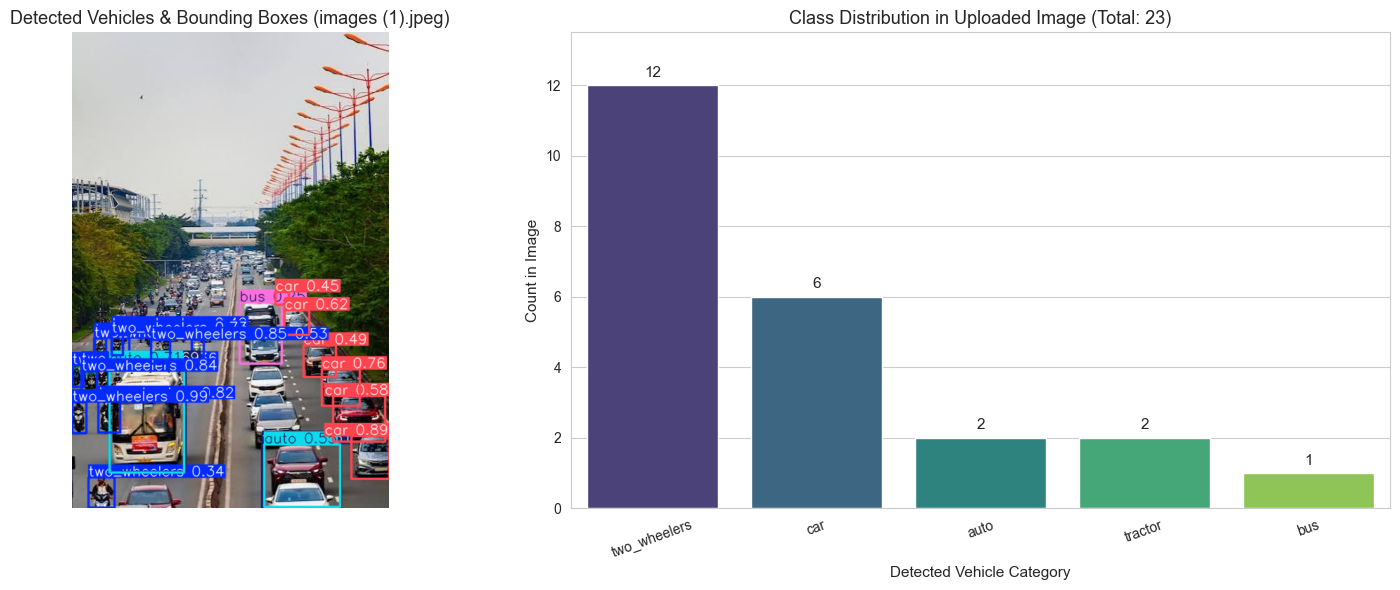


=== Bounding-Box Detections Table for 'images (1).jpeg' ===
 Box # Vehicle Class Confidence  x_min  y_min  x_max  y_max Width x Height
     1  two_wheelers     98.72%    0.8  528.6   20.1  573.0    19.3 x 44.4
     2           car     89.48%  397.2  576.2  451.0  637.9    53.8 x 61.7
     3  two_wheelers     84.73%  112.3  439.2  139.3  473.5    27.0 x 34.3
     4  two_wheelers     83.88%   13.9  484.1   35.9  516.2    22.0 x 32.1
     5  two_wheelers     81.63%   37.8  523.9   68.6  572.0    30.8 x 48.1
     6           car     76.19%  355.8  481.8  409.0  533.4    53.2 x 51.6
     7  two_wheelers     73.43%   56.6  430.6   72.1  461.8    15.5 x 31.2
     8          auto     70.70%   53.9  473.3  160.0  628.4  106.1 x 155.1
     9       tractor     68.56%   53.5  473.2  161.2  627.6  107.7 x 154.4
    10           car     62.43%  302.8  397.1  337.4  432.1    34.6 x 35.0
    11           car     58.28%  371.3  519.7  445.0  584.5    73.7 x 64.8
    12          auto     54.83%  273.7 

In [15]:
from collections import Counter
import cv2
from google.colab import files
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from ultralytics import YOLO

# 1. Load your newly trained custom Indian Vehicle model
custom_model = YOLO("/content/runs/indian_vehicle_detector/weights/best.pt")

# 2. Upload your test image from your Mac Downloads folder
uploaded = files.upload()
test_img = list(uploaded.keys())[0]

# 3. Run detection on your uploaded image
device_id = 0 if torch.cuda.is_available() else "cpu"
results = custom_model.predict(
    source=test_img, device=device_id, conf=0.25, verbose=False
)[0]

# 4. Extract Bounding Boxes, Confidence Scores & Class Distribution for THIS uploaded image
names = results.names
boxes = results.boxes
bbox_rows = []
detected_classes = []

for idx, box in enumerate(boxes, start=1):
  cls_id = int(box.cls[0].item())
  cls_name = names[cls_id]
  conf = float(box.conf[0].item())
  x1, y1, x2, y2 = [round(v, 1) for v in box.xyxy[0].tolist()]
  w, h = round(x2 - x1, 1), round(y2 - y1, 1)

  detected_classes.append(cls_name)
  bbox_rows.append({
      "Box #": idx,
      "Vehicle Class": cls_name,
      "Confidence": f"{conf:.2%}",
      "x_min": x1,
      "y_min": y1,
      "x_max": x2,
      "y_max": y2,
      "Width x Height": f"{w} x {h}",
  })

df_detections = pd.DataFrame(bbox_rows)

# 5. Plot Side-by-Side Graphical Output: Annotated Image (Left) + Class Distribution (Right)
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

annotated_rgb = cv2.cvtColor(results.plot(), cv2.COLOR_BGR2RGB)
axes[0].imshow(annotated_rgb)
axes[0].set_title(
    f"Detected Vehicles & Bounding Boxes ({test_img})",
    fontsize=13,
    fontweight="bold",
)
axes[0].axis("off")

if detected_classes:
  counts = Counter(detected_classes)
  cat_labels = list(counts.keys())
  cat_values = list(counts.values())

  bars = sns.barplot(
      x=cat_labels,
      y=cat_values,
      ax=axes[1],
      palette="viridis",
      hue=cat_labels,
      legend=False,
  )
  axes[1].set_title(
      f"Class Distribution in Uploaded Image (Total: {len(detected_classes)})",
      fontsize=13,
      fontweight="bold",
  )
  axes[1].set_xlabel("Detected Vehicle Category", fontsize=11)
  axes[1].set_ylabel("Count in Image", fontsize=11)
  axes[1].set_ylim(0, max(cat_values) + 1.5)
  axes[1].tick_params(axis="x", rotation=20)

  for bar in bars.patches:
    val = int(bar.get_height())
    axes[1].annotate(
        f"{val}",
        (bar.get_x() + bar.get_width() / 2.0, val),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        xytext=(0, 4),
        textcoords="offset points",
    )
else:
  axes[1].text(
      0.5,
      0.5,
      "No vehicles detected above confidence threshold",
      ha="center",
      va="center",
  )
  axes[1].set_title("Class Distribution", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig("uploaded_image_detection_report.png", dpi=150)
plt.show()

# 6. Display Exact Bounding-Box Coordinates Table for Your Uploaded Image
print(f"\n=== Bounding-Box Detections Table for '{test_img}' ===")
if not df_detections.empty:
  print(df_detections.to_string(index=False))
else:
  print("No bounding boxes detected.")